In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/hidden-signal-rebuild-the-data-generating-process/sample_submission.csv
/kaggle/input/competitions/hidden-signal-rebuild-the-data-generating-process/train.csv
/kaggle/input/competitions/hidden-signal-rebuild-the-data-generating-process/test.csv


In [2]:

# ============================================================
# HIDDEN SIGNAL — CIPHER'S INVESTIGATION
# Cell 1: Find, load, and inspect the competition data
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np

# 1. Find CSV files attached to this Kaggle notebook
input_dir = Path("/kaggle/input")
csv_files = list(input_dir.rglob("*.csv"))

print("CSV files available:")
for file in csv_files:
    print(" -", file)

# 2. Identify the training and test datasets
train_matches = [
    f for f in csv_files
    if "train" in f.name.lower()
    and "sample" not in f.name.lower()
]
test_matches = [
    f for f in csv_files
    if "test" in f.name.lower()
    and "sample" not in f.name.lower()
]

if not train_matches or not test_matches:
    raise FileNotFoundError(
        "\nI couldn't find both train and test CSV files. "
        "In Kaggle, click Add Input and attach the competition dataset, "
        "then run this cell again."
    )

# Use the first matching files
train_path = train_matches[0]
test_path = test_matches[0]

train = pd.read_csv(train_path)
test = pd.read_csv(test_path)

# 3. Report the dataset structure
print("\n" + "=" * 60)
print("TRAINING DATA")
print("=" * 60)
print("Shape:", train.shape)
print("\nFirst five rows:")
display(train.head())

print("\nColumn names:")
print(train.columns.tolist())

print("\nMissing values per column:")
display(train.isna().sum().to_frame("missing_values"))

print("\n" + "=" * 60)
print("TEST DATA")
print("=" * 60)
print("Shape:", test.shape)
print("\nFirst five rows:")
display(test.head())

# 4. Check the target column
target_candidates = [
    c for c in train.columns
    if c.lower() in ["target", "y"]
]

if target_candidates:
    TARGET = target_candidates[0]
    print(f"\nTarget column: {TARGET}")
    display(train[TARGET].describe().to_frame("target_summary"))
else:
    TARGET = None
    print(
        "\nCouldn't automatically identify the target column. "
        "We'll inspect the column names before proceeding."
    )

print("\nCipher's initial check complete.")


CSV files available:
 - /kaggle/input/competitions/hidden-signal-rebuild-the-data-generating-process/sample_submission.csv
 - /kaggle/input/competitions/hidden-signal-rebuild-the-data-generating-process/train.csv
 - /kaggle/input/competitions/hidden-signal-rebuild-the-data-generating-process/test.csv

TRAINING DATA
Shape: (20000, 19)

First five rows:


,id,x01,x02,x03,x04,x05,x06,x07,x08,x09,x10,x11,x12,x13,x14,x15,cat_a,cat_b,target
0,0,-1.9264,-1.2008,-1.2350,6.1766,-0.0740,6.8284,0.2923,2.2510,-3.1050,2.4369,1.0852,84.0378,3.0,4.3291,0.0,beta,high,7.7573
1,1,0.8395,-1.6291,-0.0168,6.6240,0.4914,6.7086,-0.6226,NaN,1.2618,5.5839,0.8483,48.2500,1.0,0.5214,1.0,gamma,mid,9.9856
2,2,-0.1964,0.5616,0.3463,3.3019,-0.6504,2.1182,0.0738,3.0147,-0.9211,0.7939,0.1143,6.1438,1.0,1.6480,0.0,alpha,low,2.7689
3,3,-0.7770,0.9235,0.4015,1.3832,-0.1228,5.0098,0.4776,4.6282,-1.2561,1.6747,1.0600,32.4258,4.0,0.8155,0.0,gamma,mid,4.0505
4,4,-0.8705,2.0550,-2.0592,5.8785,0.4697,1.9482,-1.4155,2.2495,0.1705,2.9241,-1.0938,39.6828,3.0,4.4250,1.0,beta,low,-7.6063



Column names:
['id', 'x01', 'x02', 'x03', 'x04', 'x05', 'x06', 'x07', 'x08', 'x09', 'x10', 'x11', 'x12', 'x13', 'x14', 'x15', 'cat_a', 'cat_b', 'target']

Missing values per column:


,missing_values
id,0
x01,0
x02,804
x03,0
x04,0
x05,805
x06,0
x07,0
x08,778
x09,0



TEST DATA
Shape: (12000, 18)

First five rows:


,id,x01,x02,x03,x04,x05,x06,x07,x08,x09,x10,x11,x12,x13,x14,x15,cat_a,cat_b
0,20000,-2.7339,0.3862,0.3399,7.0637,NaN,4.5496,-0.0246,1.0798,-2.4551,2.4821,0.2510,0.7942,4.0,0.9006,1.0,beta,mid
1,20001,-0.8446,1.1080,1.0487,1.2466,1.0830,1.6931,1.0027,6.0872,-1.6605,NaN,-1.3433,11.5321,3.0,0.0471,0.0,gamma,high
2,20002,2.1764,-0.7611,-1.1590,5.7104,0.8749,6.5758,0.1206,5.4461,3.0926,3.3328,-0.4461,72.5453,0.0,1.8155,1.0,delta,high
3,20003,-3.3554,-0.6410,0.2085,2.2551,1.2969,7.7297,0.2906,2.3270,-2.7091,4.7089,0.2375,4.0111,7.0,0.2304,0.0,alpha,high
4,20004,-2.8611,-1.4582,0.9899,4.6471,NaN,6.1213,0.0958,1.9981,-3.8702,5.3439,0.5989,NaN,2.0,0.7433,1.0,gamma,low



Target column: target


,target_summary
count,20000.000000
mean,8.009091
std,4.411777
min,-11.481900
25%,5.056975
50%,7.949550
75%,10.917100
max,32.708400



Cipher's initial check complete.


1. TARGET DISTRIBUTION
count    20000.000000
mean         8.009091
std          4.411777
min        -11.481900
25%          5.056975
50%          7.949550
75%         10.917100
max         32.708400
Name: target, dtype: float64

Skewness: 0.1096


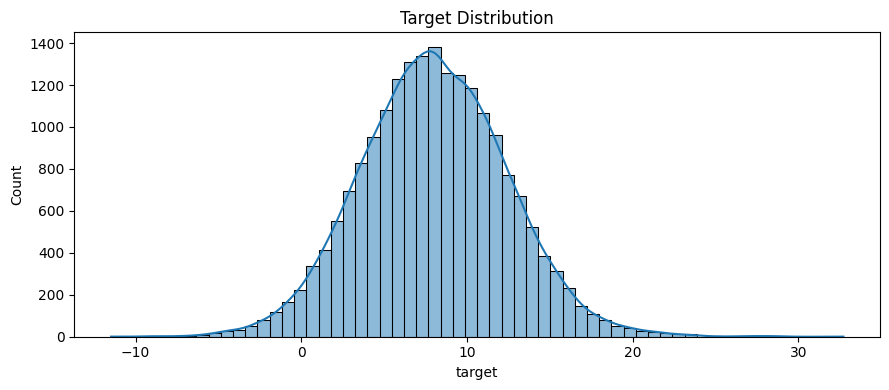


2. NUMERIC FEATURES MOST CORRELATED WITH TARGET


,pearson_correlation
x01,0.419661
x09,0.381148
x06,0.358639
x10,0.274029
x04,0.213288
x08,0.193979
x07,0.045116
x14,-0.010230
x13,0.008342
x15,0.007903


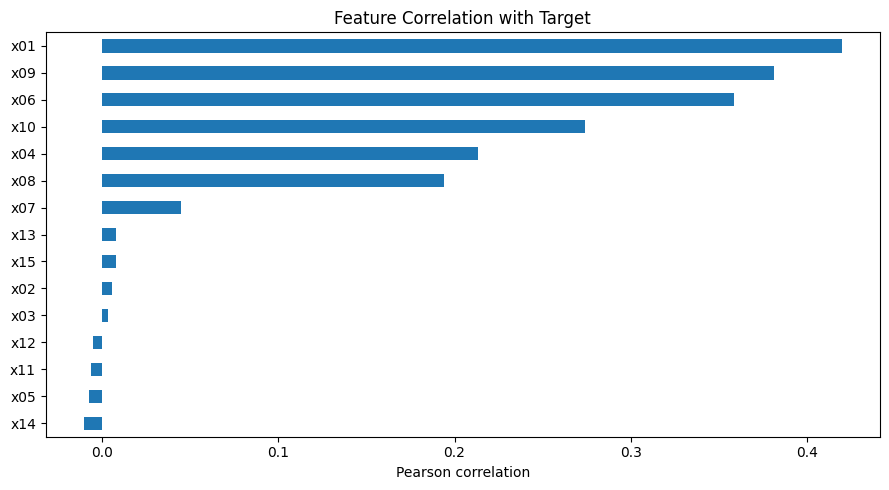


3. TARGET BY CAT_A


,count,mean,std,median
cat_a,,,,
gamma,4064,6.546815,4.573278,6.5632
alpha,6027,7.520296,4.165341,7.3765
delta,2962,8.024391,4.399588,7.9722
beta,5043,9.020096,4.183061,8.9317
epsilon,1904,9.975923,4.070946,9.8638


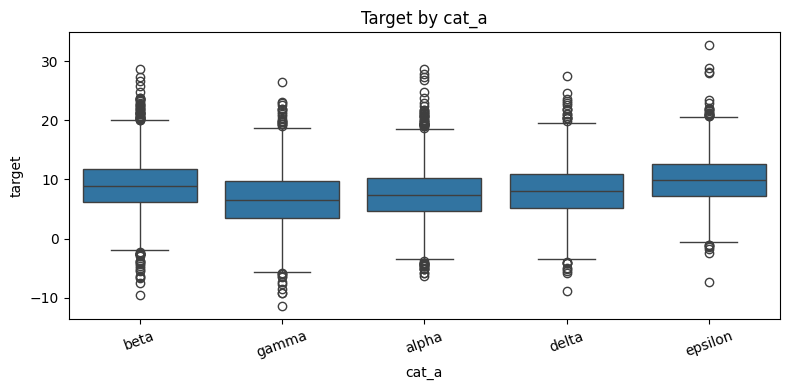


3. TARGET BY CAT_B


,count,mean,std,median
cat_b,,,,
low,6719,7.966167,4.347655,7.91650
mid,6670,7.970781,4.473720,7.92815
high,6611,8.091369,4.413058,7.99610


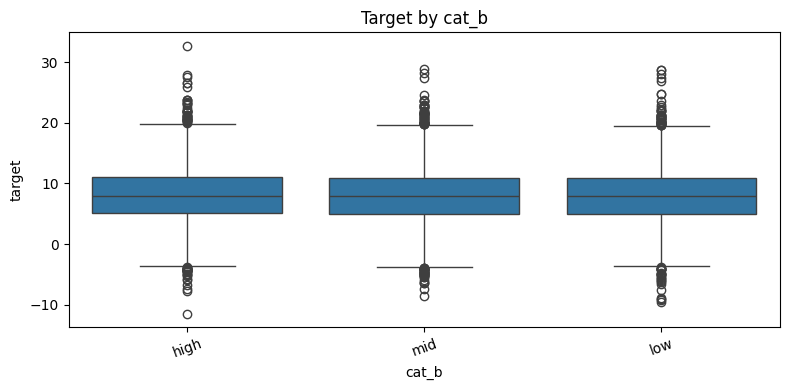


4. TARGET BY ID ORDER
ID-target correlation: 0.00407


,count,mean,std
id,,,
"(-0.001, 1999.9]",2000,8.047799,4.509151
"(1999.9, 3999.8]",2000,7.923590,4.366177
"(3999.8, 5999.7]",2000,8.085782,4.459191
"(5999.7, 7999.6]",2000,7.840609,4.326121
"(7999.6, 9999.5]",2000,8.052413,4.474355
"(9999.5, 11999.4]",2000,7.980088,4.365642
"(11999.4, 13999.3]",2000,8.071900,4.445530
"(13999.3, 15999.2]",2000,8.059418,4.454087
"(15999.2, 17999.1]",2000,7.909001,4.442499


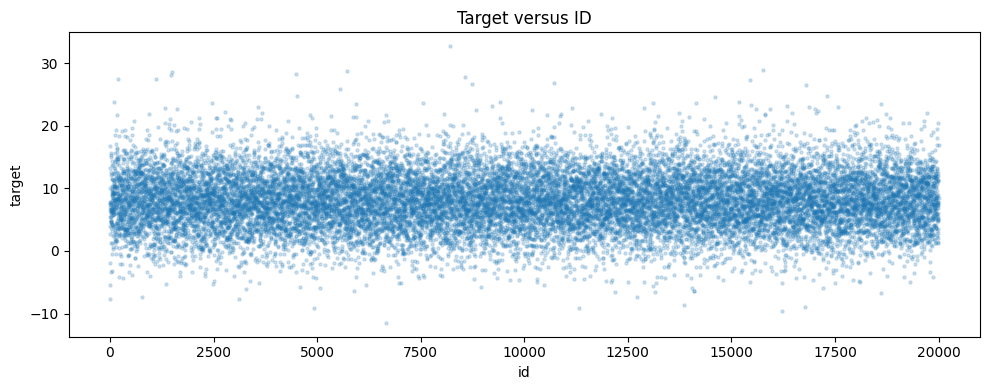


5. TARGET FOR ROWS WITH/WITHOUT MISSING FEATURES


,feature,missing_count,target_mean_missing,target_mean_present,target_std_missing,target_std_present
0,x02,804,7.9015,8.0136,4.2018,4.4204
1,x05,805,8.3286,7.9957,4.4926,4.4080
2,x08,778,8.0989,8.0055,4.4759,4.4092
3,x10,755,7.8683,8.0146,4.2423,4.4183
4,x12,759,8.0631,8.0070,4.1908,4.4204



Cipher's first diagnostic scan is complete.


In [3]:

# ============================================================
# HIDDEN SIGNAL — CIPHER'S INVESTIGATION
# Cell 2: Target relationships and feature diagnostics
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

# Identify features
TARGET = "target"
ID_COL = "id"

numeric_features = [
    c for c in train.select_dtypes(include=np.number).columns
    if c not in [TARGET, ID_COL]
]
categorical_features = [
    c for c in train.select_dtypes(exclude=np.number).columns
    if c != TARGET
]

# 1. Target distribution
print("=" * 60)
print("1. TARGET DISTRIBUTION")
print("=" * 60)
print(train[TARGET].describe())
print("\nSkewness:", round(train[TARGET].skew(), 4))

plt.figure(figsize=(9, 4))
sns.histplot(train[TARGET], bins=60, kde=True)
plt.title("Target Distribution")
plt.xlabel("target")
plt.tight_layout()
plt.show()

# 2. Numeric correlations with target
print("\n" + "=" * 60)
print("2. NUMERIC FEATURES MOST CORRELATED WITH TARGET")
print("=" * 60)

correlations = (
    train[numeric_features + [TARGET]]
    .corr(numeric_only=True)[TARGET]
    .drop(TARGET)
    .sort_values(key=lambda s: s.abs(), ascending=False)
)

display(correlations.to_frame("pearson_correlation"))

plt.figure(figsize=(9, 5))
correlations.sort_values().plot(kind="barh")
plt.title("Feature Correlation with Target")
plt.xlabel("Pearson correlation")
plt.tight_layout()
plt.show()

# 3. Category-level target statistics
for col in categorical_features:
    print(f"\n{'=' * 60}\n3. TARGET BY {col.upper()}\n{'=' * 60}")
    display(
        train.groupby(col, observed=False)[TARGET]
        .agg(["count", "mean", "std", "median"])
        .sort_values("mean")
    )

    plt.figure(figsize=(8, 4))
    sns.boxplot(data=train, x=col, y=TARGET)
    plt.title(f"Target by {col}")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

# 4. Check whether ID has a visible relationship with target
print("\n" + "=" * 60)
print("4. TARGET BY ID ORDER")
print("=" * 60)

id_corr = train[ID_COL].corr(train[TARGET])
print("ID-target correlation:", round(id_corr, 5))

# Compare target averages across ten consecutive ID groups
id_groups = pd.qcut(train[ID_COL], q=10, duplicates="drop")
id_summary = train.groupby(id_groups, observed=False)[TARGET].agg(
    ["count", "mean", "std"]
)
display(id_summary)

plt.figure(figsize=(10, 4))
plt.scatter(train[ID_COL], train[TARGET], s=5, alpha=0.2)
plt.title("Target versus ID")
plt.xlabel("id")
plt.ylabel("target")
plt.tight_layout()
plt.show()

# 5. Missing-value comparison
print("\n" + "=" * 60)
print("5. TARGET FOR ROWS WITH/WITHOUT MISSING FEATURES")
print("=" * 60)

missing_features = [
    c for c in numeric_features if train[c].isna().any()
]

missing_rows = []
for col in missing_features:
    missing_rows.append({
        "feature": col,
        "missing_count": int(train[col].isna().sum()),
        "target_mean_missing": train.loc[train[col].isna(), TARGET].mean(),
        "target_mean_present": train.loc[train[col].notna(), TARGET].mean(),
        "target_std_missing": train.loc[train[col].isna(), TARGET].std(),
        "target_std_present": train.loc[train[col].notna(), TARGET].std(),
    })

display(pd.DataFrame(missing_rows).round(4))

print("\nCipher's first diagnostic scan is complete.")


In [4]:

# ============================================================
# HIDDEN SIGNAL — CIPHER'S INVESTIGATION
# Cell 3: Compare two baseline regression models
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error

TARGET = "target"

# Keep ID out of the predictors for this first comparison
FEATURES = [
    c for c in train.columns
    if c not in [TARGET, "id"]
]

X = train[FEATURES].copy()
y = train[TARGET].copy()

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

# Fixed split so future experiments can be compared fairly
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

def make_preprocessor():
    numeric_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median"))
    ])

    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    return ColumnTransformer([
        ("numeric", numeric_pipe, numeric_features),
        ("categorical", categorical_pipe, categorical_features)
    ])

models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=250,
        min_samples_leaf=2,
        max_features=0.9,
        n_jobs=-1,
        random_state=42
    ),
    "HistGradientBoosting": Pipeline([
        ("preprocessor", make_preprocessor()),
        ("model", HistGradientBoostingRegressor(
            max_iter=250,
            learning_rate=0.06,
            max_leaf_nodes=31,
            l2_regularization=1.0,
            random_state=42
        ))
    ])
}

results = []

for name, model in models.items():
    print(f"Training {name}...")

    if name == "Random Forest":
        model = Pipeline([
            ("preprocessor", make_preprocessor()),
            ("model", model)
        ])

    model.fit(X_train, y_train)
    predictions = model.predict(X_valid)

    rmse = np.sqrt(mean_squared_error(y_valid, predictions))
    results.append({"model": name, "validation_RMSE": rmse})

    print(f"{name} RMSE: {rmse:.5f}")

results_df = pd.DataFrame(results).sort_values("validation_RMSE")
print("\nBaseline comparison — lower RMSE is better:")
display(results_df)

print("\nValidation rows:", len(X_valid))
print("Training rows used for fitting:", len(X_train))


Training Random Forest...
Random Forest RMSE: 2.51399
Training HistGradientBoosting...
HistGradientBoosting RMSE: 1.59439

Baseline comparison — lower RMSE is better:


,model,validation_RMSE
1,HistGradientBoosting,1.594385
0,Random Forest,2.513994



Validation rows: 4000
Training rows used for fitting: 16000


In [5]:

# ============================================================
# HIDDEN SIGNAL — CIPHER'S INVESTIGATION
# Cell 4: CatBoost benchmark
# ============================================================

import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error

try:
    from catboost import CatBoostRegressor

    TARGET = "target"
    FEATURES = [c for c in train.columns if c not in [TARGET, "id"]]

    X = train[FEATURES].copy()
    y = train[TARGET].copy()

    X_train_cb = X.loc[X_train.index].copy()
    X_valid_cb = X.loc[X_valid.index].copy()

    # CatBoost expects categorical columns as strings.
    cat_cols = ["cat_a", "cat_b"]
    for col in cat_cols:
        X_train_cb[col] = X_train_cb[col].astype(str)
        X_valid_cb[col] = X_valid_cb[col].astype(str)

    model_cb = CatBoostRegressor(
        iterations=1500,
        depth=7,
        learning_rate=0.04,
        loss_function="RMSE",
        eval_metric="RMSE",
        verbose=200,
        random_seed=42,
        allow_writing_files=False
    )

    model_cb.fit(
        X_train_cb,
        y_train,
        cat_features=cat_cols,
        eval_set=(X_valid_cb, y_valid),
        early_stopping_rounds=150,
        verbose=200
    )

    pred_cb = model_cb.predict(X_valid_cb)
    rmse_cb = np.sqrt(mean_squared_error(y_valid, pred_cb))

    print("\n" + "=" * 55)
    print(f"CatBoost validation RMSE: {rmse_cb:.5f}")
    print(f"Previous HistGradientBoosting RMSE: 1.59439")
    print(f"Previous Random Forest RMSE: 2.51399")
    print(f"Best iteration: {model_cb.get_best_iteration()}")
    print("=" * 55)

    print("\nTop CatBoost feature importances:")
    importance = pd.Series(
        model_cb.feature_importances_,
        index=FEATURES
    ).sort_values(ascending=False)

    display(importance.to_frame("importance").head(15))

except ImportError:
    print("CatBoost is not installed in this Kaggle environment.")
    print("Keep the Cell 3 HistGradientBoosting result as our current baseline.")
    print("Tell me this message appeared, and I'll give you a tuning cell")
    print("that uses the libraries already available.")


0:	learn: 4.3335943	test: 4.2977875	best: 4.2977875 (0)	total: 79ms	remaining: 1m 58s
200:	learn: 1.7316003	test: 1.7956329	best: 1.7956329 (200)	total: 2.65s	remaining: 17.1s
400:	learn: 1.2206486	test: 1.3202841	best: 1.3202841 (400)	total: 5.07s	remaining: 13.9s
600:	learn: 1.1136747	test: 1.2546646	best: 1.2546646 (600)	total: 7.6s	remaining: 11.4s
800:	learn: 1.0516915	test: 1.2400474	best: 1.2400132 (798)	total: 10.2s	remaining: 8.88s
1000:	learn: 1.0020806	test: 1.2348050	best: 1.2347231 (996)	total: 12.7s	remaining: 6.35s
1200:	learn: 0.9587816	test: 1.2340600	best: 1.2336212 (1128)	total: 15.1s	remaining: 3.75s
Stopped by overfitting detector  (150 iterations wait)

bestTest = 1.233621168
bestIteration = 1128

Shrink model to first 1129 iterations.

CatBoost validation RMSE: 1.23362
Previous HistGradientBoosting RMSE: 1.59439
Previous Random Forest RMSE: 2.51399
Best iteration: 1128

Top CatBoost feature importances:


,importance
x01,21.954507
x02,14.168830
x05,13.071168
x03,12.852073
cat_a,10.534885
x06,10.127408
x04,6.726442
x07,4.550030
x08,4.185477
x09,0.355287


In [6]:

# ============================================================
# CIPHER CHECKPOINT — SAVE TODAY'S PROGRESS
# ============================================================

from pathlib import Path
from datetime import datetime
import json
import os

# Kaggle working directory
SAVE_DIR = Path("/kaggle/working/cipher_checkpoint")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

# 1. Save our investigation notes
checkpoint_text = """
CIPHER — HIDDEN SIGNAL INVESTIGATION
Checkpoint date: 2026-10-16

GOAL
Reverse-engineer the hidden data-generating process and minimize RMSE.

DATA
Training rows: 20,000
Test rows: 12,000
Predictors: x01-x15, cat_a, cat_b
Target: target
Missing training values: x02, x05, x08, x10, x12

DIAGNOSTICS
Target mean: 8.009091
Target standard deviation: 4.411777
Strongest marginal correlations:
x01=0.419661, x09=0.381148, x06=0.358639,
x10=0.274029, x04=0.213288, x08=0.193979

cat_a group means:
gamma=6.546815, alpha=7.520296, delta=8.024391,
beta=9.020096, epsilon=9.975923

MODEL RESULTS — SAME 80/20 VALIDATION SPLIT
Random Forest RMSE: 2.513994
HistGradientBoosting RMSE: 1.594385
CatBoost RMSE: 1.233621
CatBoost best iteration: 1128

TOP CATBOOST FEATURES
x01, x02, x05, x03, cat_a, x06, x04, x07, x08

NEXT STEP
Run Cell 5 in the notebook to inspect CatBoost feature interactions:
model_cb.get_feature_importance(type="Interaction")

Then test candidate nonlinear relationships and interactions.
Keep the validation split consistent when comparing models.

PRIVACY
Keep the Kaggle notebook private. Do not publish or invite collaborators.
"""

notes_path = SAVE_DIR / "cipher_progress_notes.txt"
notes_path.write_text(checkpoint_text.strip() + "\n", encoding="utf-8")

# 2. Save the trained CatBoost model if it exists in this session
model_path = SAVE_DIR / "catboost_best_model.cbm"

if "model_cb" in globals():
    model_cb.save_model(str(model_path))
    print("CatBoost model saved:", model_path)
else:
    print("CatBoost model not found in memory.")
    print("You can rerun Cells 1–4 tomorrow to recreate it.")

# 3. Save a machine-readable summary
summary = {
    "checkpoint_date": "2026-10-16",
    "train_rows": 20000,
    "test_rows": 12000,
    "validation_split": "train_test_split(test_size=0.20, random_state=42)",
    "rmse": {
        "Random Forest": 2.513994,
        "HistGradientBoosting": 1.594385,
        "CatBoost": 1.233621168
    },
    "catboost_best_iteration": 1128,
    "next_step": "Run Cell 5: inspect CatBoost feature interactions"
}

summary_path = SAVE_DIR / "checkpoint_summary.json"
summary_path.write_text(
    json.dumps(summary, indent=2),
    encoding="utf-8"
)

print("\n" + "=" * 55)
print("CIPHER CHECKPOINT CREATED")
print("=" * 55)
print("Notes:", notes_path)
print("Summary:", summary_path)
print("\nFiles currently saved:")
for path in SAVE_DIR.iterdir():
    print(f" - {path.name} ({path.stat().st_size:,} bytes)")

print("\nIMPORTANT: Download these files before ending your session.")


CatBoost model saved: /kaggle/working/cipher_checkpoint/catboost_best_model.cbm

CIPHER CHECKPOINT CREATED
Notes: /kaggle/working/cipher_checkpoint/cipher_progress_notes.txt
Summary: /kaggle/working/cipher_checkpoint/checkpoint_summary.json

Files currently saved:
 - checkpoint_summary.json (374 bytes)
 - cipher_progress_notes.txt (1,148 bytes)
 - catboost_best_model.cbm (2,488,052 bytes)

IMPORTANT: Download these files before ending your session.


In [7]:

# CELL 5 — Investigate feature interactions

interaction_values = model_cb.get_feature_importance(
    type="Interaction"
)

interaction_df = pd.DataFrame(
    interaction_values,
    columns=[
        "feature_index_1",
        "feature_index_2",
        "importance"
    ]
)

interaction_df["feature_1"] = interaction_df[
    "feature_index_1"
].map(lambda i: FEATURES[int(i)])

interaction_df["feature_2"] = interaction_df[
    "feature_index_2"
].map(lambda i: FEATURES[int(i)])

interaction_df = interaction_df[
    ["feature_1", "feature_2", "importance"]
].sort_values(
    "importance",
    ascending=False
)

display(interaction_df.head(20).reset_index(drop=True))


,feature_1,feature_2,importance
0,x02,x03,14.096111
1,x07,cat_a,5.626217
2,x05,x06,5.468889
3,x01,x05,4.878121
4,x01,x06,3.602874
5,x05,cat_a,3.064691
6,x05,x08,2.669262
7,x04,x05,2.482990
8,x02,x05,2.114737
9,x06,cat_a,1.920201


In [8]:

# CELL 6 — Create a first submission CSV

import pandas as pd
from pathlib import Path

# Load test data if it is not already in memory
if "test" not in globals():
    test = pd.read_csv("/kaggle/input/hidden-signal-rebuild-the-data-generating-process/test.csv")

# Use the same features and order as training
X_test = test[FEATURES].copy()

# Predict using our trained CatBoost model
test_predictions = model_cb.predict(X_test)

# Start with the sample template if available
sample_path = Path(
    "/kaggle/input/hidden-signal-rebuild-the-data-generating-process/sample_submission.csv"
)

if sample_path.exists():
    submission = pd.read_csv(sample_path)
    print("Sample submission columns:", submission.columns.tolist())
else:
    # Fallback only; verify against the competition's template
    submission = pd.DataFrame({"target": test_predictions})

# Fill the target column in the provided template.
# If the target column has another name, stop and inspect the template.
target_columns = [
    c for c in submission.columns
    if c.lower() == "target"
]

if len(target_columns) != 1:
    raise ValueError(
        "Check sample_submission.csv and set the correct prediction column. "
        f"Columns found: {submission.columns.tolist()}"
    )

submission[target_columns[0]] = test_predictions

# Save locally in Kaggle's working directory
output_path = "/kaggle/working/submission.csv"
submission.to_csv(output_path, index=False)

print("Saved:", output_path)
print("Submission shape:", submission.shape)
display(submission.head())


Saved: /kaggle/working/submission.csv
Submission shape: (12000, 1)


,target
0,7.923415
1,6.815720
2,13.297704
3,8.539253
4,3.016149


In [9]:

# CELL 7 — Test the strongest suspected interaction

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from catboost import CatBoostRegressor

# Re-create the same validation split
X = train[FEATURES].copy()
y = train["target"].copy()

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Keep categorical columns as strings, including missing values
cat_features = ["cat_a", "cat_b"]

for col in cat_features:
    X_train[col] = X_train[col].fillna("Missing").astype(str)
    X_valid[col] = X_valid[col].fillna("Missing").astype(str)

# Baseline: same CatBoost settings, no manual interaction
baseline = CatBoostRegressor(
    iterations=1129,
    depth=7,
    learning_rate=0.04,
    loss_function="RMSE",
    random_seed=42,
    verbose=False,
    allow_writing_files=False
)

baseline.fit(X_train, y_train, cat_features=cat_features)
baseline_pred = baseline.predict(X_valid)
baseline_rmse = np.sqrt(mean_squared_error(y_valid, baseline_pred))

# Experiment: add explicit product interaction
X_train_int = X_train.copy()
X_valid_int = X_valid.copy()

X_train_int["x02_x03_product"] = (
    X_train_int["x02"] * X_train_int["x03"]
)
X_valid_int["x02_x03_product"] = (
    X_valid_int["x02"] * X_valid_int["x03"]
)

# Missing values in either input remain missing in the product
experiment = CatBoostRegressor(
    iterations=1129,
    depth=7,
    learning_rate=0.04,
    loss_function="RMSE",
    random_seed=42,
    verbose=False,
    allow_writing_files=False
)

experiment.fit(X_train_int, y_train, cat_features=cat_features)
experiment_pred = experiment.predict(X_valid_int)
experiment_rmse = np.sqrt(
    mean_squared_error(y_valid, experiment_pred)
)

print(f"Baseline RMSE:             {baseline_rmse:.6f}")
print(f"With x02*x03 RMSE:         {experiment_rmse:.6f}")
print(f"RMSE change:               {experiment_rmse - baseline_rmse:+.6f}")

if experiment_rmse < baseline_rmse:
    print("The explicit product improved validation RMSE.")
else:
    print("The explicit product did not improve validation RMSE.")


Baseline RMSE:             1.233621
With x02*x03 RMSE:         1.237804
RMSE change:               +0.004183
The explicit product did not improve validation RMSE.


In [10]:

# CELL 8 — Test x05 * x06

X_train_int2 = X_train.copy()
X_valid_int2 = X_valid.copy()

X_train_int2["x05_x06_product"] = (
    X_train_int2["x05"] * X_train_int2["x06"]
)
X_valid_int2["x05_x06_product"] = (
    X_valid_int2["x05"] * X_valid_int2["x06"]
)

model_x05_x06 = CatBoostRegressor(
    iterations=1129,
    depth=7,
    learning_rate=0.04,
    loss_function="RMSE",
    random_seed=42,
    verbose=False,
    allow_writing_files=False
)

model_x05_x06.fit(
    X_train_int2,
    y_train,
    cat_features=cat_features
)

pred_x05_x06 = model_x05_x06.predict(X_valid_int2)

rmse_x05_x06 = np.sqrt(
    mean_squared_error(y_valid, pred_x05_x06)
)

print(f"Baseline RMSE:          {baseline_rmse:.6f}")
print(f"With x05*x06 RMSE:      {rmse_x05_x06:.6f}")
print(f"RMSE change:            {rmse_x05_x06 - baseline_rmse:+.6f}")


Baseline RMSE:          1.233621
With x05*x06 RMSE:      1.235537
RMSE change:            +0.001915


In [12]:

# CELL 8 — Test x05 * x06

X_train_int2 = X_train.copy()
X_valid_int2 = X_valid.copy()

X_train_int2["x05_x06_product"] = (
    X_train_int2["x05"] * X_train_int2["x06"]
)
X_valid_int2["x05_x06_product"] = (
    X_valid_int2["x05"] * X_valid_int2["x06"]
)

model_x05_x06 = CatBoostRegressor(
    iterations=1129,
    depth=7,
    learning_rate=0.04,
    loss_function="RMSE",
    random_seed=42,
    verbose=False,
    allow_writing_files=False
)

model_x05_x06.fit(
    X_train_int2,
    y_train,
    cat_features=cat_features
)

pred_x05_x06 = model_x05_x06.predict(X_valid_int2)

rmse_x05_x06 = np.sqrt(
    mean_squared_error(y_valid, pred_x05_x06)
)

print(f"Baseline RMSE:          {baseline_rmse:.6f}")
print(f"With x05*x06 RMSE:      {rmse_x05_x06:.6f}")
print(f"RMSE change:            {rmse_x05_x06 - baseline_rmse:+.6f}")


Baseline RMSE:          1.233621
With x05*x06 RMSE:      1.235537
RMSE change:            +0.001915


In [13]:
print("Combined-category model exists:",
      "model_cat_a_x07" in globals())
print("Combined-category score exists:",
      "rmse_cat_a_x07" in globals())

Combined-category model exists: False
Combined-category score exists: False


In [14]:

# CELL 9 — Test x07 combined with cat_a

import numpy as np
import pandas as pd
from catboost import CatBoostRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

# Rebuild the same validation split
X = train[FEATURES].copy()
y = train["target"].copy()

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Prepare categorical columns consistently
for df in (X_train, X_valid):
    for col in ["cat_a", "cat_b"]:
        df[col] = df[col].fillna("Missing").astype(str)

# Baseline model
baseline = CatBoostRegressor(
    iterations=1129,
    depth=7,
    learning_rate=0.04,
    loss_function="RMSE",
    random_seed=42,
    verbose=False,
    allow_writing_files=False
)

baseline.fit(
    X_train, y_train,
    cat_features=["cat_a", "cat_b"]
)

baseline_pred = baseline.predict(X_valid)
baseline_rmse = np.sqrt(
    mean_squared_error(y_valid, baseline_pred)
)

# Build combined category
def make_x07_cat_a(df):
    x07_text = df["x07"].map(
        lambda v: "Missing" if pd.isna(v) else str(v)
    )
    cat_a_text = df["cat_a"].fillna("Missing").astype(str)
    return cat_a_text + "__x07__" + x07_text

X_train_cat = X_train.copy()
X_valid_cat = X_valid.copy()

X_train_cat["cat_a_x07"] = make_x07_cat_a(X_train_cat)
X_valid_cat["cat_a_x07"] = make_x07_cat_a(X_valid_cat)

# Train experiment
model_cat_a_x07 = CatBoostRegressor(
    iterations=1129,
    depth=7,
    learning_rate=0.04,
    loss_function="RMSE",
    random_seed=42,
    verbose=False,
    allow_writing_files=False
)

model_cat_a_x07.fit(
    X_train_cat,
    y_train,
    cat_features=["cat_a", "cat_b", "cat_a_x07"]
)

pred_cat_a_x07 = model_cat_a_x07.predict(X_valid_cat)
rmse_cat_a_x07 = np.sqrt(
    mean_squared_error(y_valid, pred_cat_a_x07)
)

print(f"Baseline RMSE:          {baseline_rmse:.6f}")
print(f"With combined category: {rmse_cat_a_x07:.6f}")
print(f"RMSE change:            {rmse_cat_a_x07 - baseline_rmse:+.6f}")

Baseline RMSE:          1.233621
With combined category: 1.236372
RMSE change:            +0.002750


In [15]:

# CELL 10 — Test CatBoost depth 6

from catboost import CatBoostRegressor
from sklearn.metrics import mean_squared_error
import numpy as np

model_depth6 = CatBoostRegressor(
    iterations=1500,
    depth=6,
    learning_rate=0.04,
    loss_function="RMSE",
    random_seed=42,
    early_stopping_rounds=150,
    verbose=200,
    allow_writing_files=False
)

model_depth6.fit(
    X_train,
    y_train,
    cat_features=["cat_a", "cat_b"],
    eval_set=(X_valid, y_valid),
    use_best_model=True
)

pred_depth6 = model_depth6.predict(X_valid)
rmse_depth6 = np.sqrt(
    mean_squared_error(y_valid, pred_depth6)
)

print(f"Original best RMSE: {1.233621:.6f}")
print(f"Depth 6 RMSE:       {rmse_depth6:.6f}")
print(f"RMSE change:        {rmse_depth6 - 1.233621:+.6f}")
print("Best iteration:", model_depth6.best_iteration_)


0:	learn: 4.3401467	test: 4.3033732	best: 4.3033732 (0)	total: 19.8ms	remaining: 29.6s
200:	learn: 1.9851812	test: 2.0395249	best: 2.0395249 (200)	total: 2s	remaining: 12.9s
400:	learn: 1.3286237	test: 1.4027749	best: 1.4027749 (400)	total: 3.77s	remaining: 10.3s
600:	learn: 1.1779035	test: 1.2807086	best: 1.2807086 (600)	total: 5.59s	remaining: 8.36s
800:	learn: 1.1137767	test: 1.2476794	best: 1.2476794 (800)	total: 7.45s	remaining: 6.5s
1000:	learn: 1.0701076	test: 1.2354549	best: 1.2354549 (1000)	total: 9.32s	remaining: 4.65s
1200:	learn: 1.0346182	test: 1.2303778	best: 1.2300712 (1179)	total: 11.1s	remaining: 2.76s
1400:	learn: 1.0025407	test: 1.2287282	best: 1.2283443 (1358)	total: 13s	remaining: 917ms
1499:	learn: 0.9888482	test: 1.2286288	best: 1.2283443 (1358)	total: 14s	remaining: 0us

bestTest = 1.228344313
bestIteration = 1358

Shrink model to first 1359 iterations.
Original best RMSE: 1.233621
Depth 6 RMSE:       1.228344
RMSE change:        -0.005277
Best iteration: 1358


In [16]:

# CELL 11 — Test CatBoost depth 5

from catboost import CatBoostRegressor
from sklearn.metrics import mean_squared_error
import numpy as np

model_depth5 = CatBoostRegressor(
    iterations=1800,
    depth=5,
    learning_rate=0.04,
    loss_function="RMSE",
    random_seed=42,
    early_stopping_rounds=150,
    verbose=200,
    allow_writing_files=False
)

model_depth5.fit(
    X_train,
    y_train,
    cat_features=["cat_a", "cat_b"],
    eval_set=(X_valid, y_valid),
    use_best_model=True
)

pred_depth5 = model_depth5.predict(X_valid)
rmse_depth5 = np.sqrt(
    mean_squared_error(y_valid, pred_depth5)
)

print(f"Previous best (depth 6): {1.228344313:.6f}")
print(f"Depth 5 RMSE:            {rmse_depth5:.6f}")
print(f"RMSE change:             {rmse_depth5 - 1.228344313:+.6f}")
print("Best iteration:", model_depth5.best_iteration_)


0:	learn: 4.3438402	test: 4.3074541	best: 4.3074541 (0)	total: 8.85ms	remaining: 15.9s
200:	learn: 2.2301577	test: 2.2710627	best: 2.2710627 (200)	total: 1.4s	remaining: 11.2s
400:	learn: 1.5404207	test: 1.5950597	best: 1.5950597 (400)	total: 2.78s	remaining: 9.7s
600:	learn: 1.2903286	test: 1.3645097	best: 1.3645097 (600)	total: 4.04s	remaining: 8.05s
800:	learn: 1.1967268	test: 1.2882793	best: 1.2882793 (800)	total: 5.35s	remaining: 6.67s
1000:	learn: 1.1465776	test: 1.2601685	best: 1.2601685 (1000)	total: 6.76s	remaining: 5.39s
1200:	learn: 1.1109984	test: 1.2433124	best: 1.2432660 (1199)	total: 8.13s	remaining: 4.05s
1400:	learn: 1.0812100	test: 1.2324814	best: 1.2324111 (1390)	total: 9.64s	remaining: 2.74s
1600:	learn: 1.0569249	test: 1.2294672	best: 1.2294672 (1600)	total: 11.2s	remaining: 1.4s
1799:	learn: 1.0352463	test: 1.2290574	best: 1.2283501 (1679)	total: 12.7s	remaining: 0us

bestTest = 1.228350055
bestIteration = 1679

Shrink model to first 1680 iterations.
Previous best

In [18]:
model_lr03 = CatBoostRegressor(
    iterations=2200,
    depth=6,
    learning_rate=0.03,
    loss_function="RMSE",
    random_seed=42,
    early_stopping_rounds=180,
    verbose=200,
    allow_writing_files=False
)

model_lr03.fit(
    X_train,
    y_train,
    cat_features=["cat_a", "cat_b"],
    eval_set=(X_valid, y_valid),
    use_best_model=True
)

pred_lr03 = model_lr03.predict(X_valid)
rmse_lr03 = np.sqrt(mean_squared_error(y_valid, pred_lr03))

print(f"Current best (depth 6, LR 0.04): {1.228344313:.6f}")
print(f"New model (depth 6, LR 0.03):   {rmse_lr03:.6f}")
print(f"RMSE change:                    {rmse_lr03 - 1.228344313:+.6f}")
print("Best iteration:", model_lr03.best_iteration_)

0:	learn: 4.3597327	test: 4.3228016	best: 4.3228016 (0)	total: 10.1ms	remaining: 22.3s
200:	learn: 2.2259335	test: 2.2704668	best: 2.2704668 (200)	total: 1.98s	remaining: 19.7s
400:	learn: 1.5355250	test: 1.5950310	best: 1.5950310 (400)	total: 3.88s	remaining: 17.4s
600:	learn: 1.2764982	test: 1.3554420	best: 1.3554317 (599)	total: 5.68s	remaining: 15.1s
800:	learn: 1.1758075	test: 1.2772771	best: 1.2772771 (800)	total: 7.4s	remaining: 12.9s
1000:	learn: 1.1247354	test: 1.2473061	best: 1.2473061 (1000)	total: 9.22s	remaining: 11s
1200:	learn: 1.0895301	test: 1.2360673	best: 1.2360673 (1200)	total: 11.1s	remaining: 9.26s
1400:	learn: 1.0602743	test: 1.2305199	best: 1.2304784 (1398)	total: 12.9s	remaining: 7.36s
1600:	learn: 1.0356144	test: 1.2271489	best: 1.2271489 (1600)	total: 14.7s	remaining: 5.51s
1800:	learn: 1.0112516	test: 1.2256747	best: 1.2256491 (1798)	total: 16.7s	remaining: 3.7s
2000:	learn: 0.9891028	test: 1.2248905	best: 1.2244136 (1956)	total: 18.5s	remaining: 1.84s
Stopp

In [20]:
model_lr02 = CatBoostRegressor(
    iterations=3000,
    depth=6,
    learning_rate=0.02,
    loss_function="RMSE",
    random_seed=42,
    early_stopping_rounds=220,
    verbose=300,
    allow_writing_files=False
)

model_lr02.fit(
    X_train,
    y_train,
    cat_features=["cat_a", "cat_b"],
    eval_set=(X_valid, y_valid),
    use_best_model=True
)

pred_lr02 = model_lr02.predict(X_valid)
rmse_lr02 = np.sqrt(mean_squared_error(y_valid, pred_lr02))

print(f"Current best (LR 0.03): {1.224413575:.6f}")
print(f"New model (LR 0.02):    {rmse_lr02:.6f}")
print(f"RMSE change:            {rmse_lr02 - 1.224413575:+.6f}")
print("Best iteration:", model_lr02.best_iteration_)

0:	learn: 4.3794304	test: 4.3423443	best: 4.3423443 (0)	total: 21ms	remaining: 1m 2s
300:	learn: 2.2398971	test: 2.2870143	best: 2.2870143 (300)	total: 3.06s	remaining: 27.5s
600:	learn: 1.5442710	test: 1.6064438	best: 1.6064438 (600)	total: 5.85s	remaining: 23.4s
900:	learn: 1.2813073	test: 1.3631597	best: 1.3631597 (900)	total: 8.46s	remaining: 19.7s
1200:	learn: 1.1748597	test: 1.2782140	best: 1.2782140 (1200)	total: 11.2s	remaining: 16.8s
1500:	learn: 1.1268267	test: 1.2511069	best: 1.2511069 (1500)	total: 14.1s	remaining: 14.1s
1800:	learn: 1.0900678	test: 1.2385914	best: 1.2385914 (1800)	total: 17.1s	remaining: 11.4s
2100:	learn: 1.0582975	test: 1.2307907	best: 1.2307378 (2097)	total: 19.9s	remaining: 8.52s
2400:	learn: 1.0330927	test: 1.2277062	best: 1.2277062 (2400)	total: 22.7s	remaining: 5.66s
2700:	learn: 1.0095635	test: 1.2268281	best: 1.2266909 (2580)	total: 25.5s	remaining: 2.83s
2999:	learn: 0.9879215	test: 1.2262616	best: 1.2262019 (2994)	total: 28.5s	remaining: 0us

be

In [21]:
model_l2 = CatBoostRegressor(
    iterations=2400,
    depth=6,
    learning_rate=0.03,
    l2_leaf_reg=5,
    loss_function="RMSE",
    random_seed=42,
    early_stopping_rounds=180,
    verbose=300,
    allow_writing_files=False
)

model_l2.fit(
    X_train,
    y_train,
    cat_features=["cat_a", "cat_b"],
    eval_set=(X_valid, y_valid),
    use_best_model=True
)

pred_l2 = model_l2.predict(X_valid)
rmse_l2 = np.sqrt(mean_squared_error(y_valid, pred_l2))

print(f"Current best (L2=3): {1.224413575:.6f}")
print(f"New model (L2=5):    {rmse_l2:.6f}")
print(f"RMSE change:         {rmse_l2 - 1.224413575:+.6f}")
print("Best iteration:", model_l2.best_iteration_)

0:	learn: 4.3601696	test: 4.3232631	best: 4.3232631 (0)	total: 11.8ms	remaining: 28.3s
300:	learn: 1.8455082	test: 1.8919413	best: 1.8919413 (300)	total: 2.69s	remaining: 18.8s
600:	learn: 1.2796712	test: 1.3512788	best: 1.3512788 (600)	total: 5.37s	remaining: 16.1s
900:	learn: 1.1629045	test: 1.2599901	best: 1.2599901 (900)	total: 7.94s	remaining: 13.2s
1200:	learn: 1.1102775	test: 1.2361698	best: 1.2361698 (1200)	total: 10.4s	remaining: 10.4s
1500:	learn: 1.0695098	test: 1.2271002	best: 1.2269604 (1494)	total: 13s	remaining: 7.76s
1800:	learn: 1.0340976	test: 1.2230900	best: 1.2229951 (1792)	total: 15.7s	remaining: 5.21s
2100:	learn: 1.0019966	test: 1.2225705	best: 1.2222649 (1976)	total: 18.3s	remaining: 2.6s
Stopped by overfitting detector  (180 iterations wait)

bestTest = 1.222264891
bestIteration = 1976

Shrink model to first 1977 iterations.
Current best (L2=3): 1.224414
New model (L2=5):    1.222265
RMSE change:         -0.002149
Best iteration: 1976


In [22]:
model_l2_7 = CatBoostRegressor(
    iterations=2400,
    depth=6,
    learning_rate=0.03,
    l2_leaf_reg=7,
    loss_function="RMSE",
    random_seed=42,
    early_stopping_rounds=180,
    verbose=300,
    allow_writing_files=False
)

model_l2_7.fit(
    X_train,
    y_train,
    cat_features=["cat_a", "cat_b"],
    eval_set=(X_valid, y_valid),
    use_best_model=True
)

pred_l2_7 = model_l2_7.predict(X_valid)
rmse_l2_7 = np.sqrt(mean_squared_error(y_valid, pred_l2_7))

print(f"Current best (L2=5): {1.222264891:.6f}")
print(f"New model (L2=7):    {rmse_l2_7:.6f}")
print(f"RMSE change:         {rmse_l2_7 - 1.222264891:+.6f}")
print("Best iteration:", model_l2_7.best_iteration_)

0:	learn: 4.3605924	test: 4.3237096	best: 4.3237096 (0)	total: 11.3ms	remaining: 27s
300:	learn: 1.8712586	test: 1.9171033	best: 1.9171033 (300)	total: 2.75s	remaining: 19.2s
600:	learn: 1.2900262	test: 1.3589305	best: 1.3589305 (600)	total: 5.31s	remaining: 15.9s
900:	learn: 1.1660697	test: 1.2621078	best: 1.2621078 (900)	total: 7.8s	remaining: 13s
1200:	learn: 1.1158562	test: 1.2378326	best: 1.2378326 (1200)	total: 10.3s	remaining: 10.3s
1500:	learn: 1.0774026	test: 1.2296549	best: 1.2296549 (1500)	total: 12.9s	remaining: 7.7s
1800:	learn: 1.0433144	test: 1.2253608	best: 1.2253007 (1793)	total: 15.4s	remaining: 5.14s
2100:	learn: 1.0139186	test: 1.2236164	best: 1.2235673 (2098)	total: 18.2s	remaining: 2.59s
Stopped by overfitting detector  (180 iterations wait)

bestTest = 1.223491282
bestIteration = 2126

Shrink model to first 2127 iterations.
Current best (L2=5): 1.222265
New model (L2=7):    1.223491
RMSE change:         +0.001226
Best iteration: 2126


In [23]:
import os
import json

os.makedirs("/kaggle/working/cipher_checkpoint", exist_ok=True)

# Save the winning trained model from our L2=5 experiment
model_l2.save_model(
    "/kaggle/working/cipher_checkpoint/cipher_best_model.cbm"
)

notes = {
    "competition": "Hidden Signal: Rebuild the Data-Generating Process",
    "best_model": "CatBoostRegressor",
    "depth": 6,
    "learning_rate": 0.03,
    "l2_leaf_reg": 5,
    "best_iteration_zero_based": model_l2.best_iteration_,
    "validation_rmse": float(rmse_l2),
    "random_seed": 42,
    "status": "Best validation model; submission not yet made"
}

with open(
    "/kaggle/working/cipher_checkpoint/cipher_experiment_notes.json",
    "w"
) as f:
    json.dump(notes, f, indent=2)

print("Winning model and notes saved.")
print("Validation RMSE:", rmse_l2)
print("Best iteration:", model_l2.best_iteration_)

Winning model and notes saved.
Validation RMSE: 1.2222648939573406
Best iteration: 1976


In [25]:
import os

print("=== Kaggle input folders ===")
if os.path.exists("/kaggle/input"):
    for name in os.listdir("/kaggle/input"):
        print("Folder:", os.path.join("/kaggle/input", name))
else:
    print("/kaggle/input does not exist")

print("\n=== CSV files found ===")
for root, dirs, files in os.walk("/kaggle/input"):
    for name in files:
        if name.lower().endswith(".csv"):
            print(os.path.join(root, name))

print("\n=== Variables already in memory ===")
for name in ["train", "test", "submission", "final_model"]:
    print(f"{name}: {'available' if name in globals() else 'not available'}")

=== Kaggle input folders ===
Folder: /kaggle/input/competitions

=== CSV files found ===
/kaggle/input/competitions/hidden-signal-rebuild-the-data-generating-process/sample_submission.csv
/kaggle/input/competitions/hidden-signal-rebuild-the-data-generating-process/train.csv
/kaggle/input/competitions/hidden-signal-rebuild-the-data-generating-process/test.csv

=== Variables already in memory ===
train: available
test: available
submission: available
final_model: available


In [28]:
import os
import pandas as pd

sample_path = (
    "/kaggle/input/competitions/"
    "hidden-signal-rebuild-the-data-generating-process/"
    "sample_submission.csv"
)

print("File exists:", os.path.exists(sample_path))

sample = pd.read_csv(sample_path)
print("Template shape:", sample.shape)
print("Template columns:", sample.columns.tolist())
display(sample.head())

File exists: True
Template shape: (12000, 2)
Template columns: ['id', 'target']


,id,target
0,20000,8.0091
1,20001,8.0091
2,20002,8.0091
3,20003,8.0091
4,20004,8.0091


In [29]:
import os
import numpy as np
import pandas as pd

DATA_DIR = (
    "/kaggle/input/competitions/"
    "hidden-signal-rebuild-the-data-generating-process"
)

# Load the official template
sample = pd.read_csv(os.path.join(DATA_DIR, "sample_submission.csv"))

# Prepare test features in the same order used during training
FEATURES = [c for c in train.columns if c not in ["id", "target"]]
CAT_FEATURES = ["cat_a", "cat_b"]

X_test_final = test[FEATURES].copy()

for col in CAT_FEATURES:
    X_test_final[col] = X_test_final[col].fillna("Missing").astype(str)

# Generate predictions with our saved-in-memory winning model
predictions = final_model.predict(X_test_final)

# Verify before writing
assert len(predictions) == len(sample) == 12000
assert np.isfinite(predictions).all()
assert sample.columns.tolist() == ["id", "target"]
assert np.array_equal(sample["id"].to_numpy(), test["id"].to_numpy())

# Replace placeholders with genuine model predictions
submission_final = sample.copy()
submission_final["target"] = predictions

output_path = "/kaggle/working/submission.csv"
submission_final.to_csv(output_path, index=False)

# Read the saved CSV back and validate it
check = pd.read_csv(output_path)

assert check.shape == (12000, 2)
assert check.columns.tolist() == ["id", "target"]
assert check.isna().sum().sum() == 0
assert np.isfinite(check["target"]).all()
assert np.array_equal(check["id"].to_numpy(), test["id"].to_numpy())

print("PASS: submission.csv created and verified.")
print("Location:", output_path)
print("Shape:", check.shape)
print("Missing values:", int(check.isna().sum().sum()))
print("Prediction range:",
      round(check["target"].min(), 5),
      "to",
      round(check["target"].max(), 5))
print("\nFirst five predictions:")
print(check.head())

PASS: submission.csv created and verified.
Location: /kaggle/working/submission.csv
Shape: (12000, 2)
Missing values: 0
Prediction range: -7.98376 to 25.57099

First five predictions:
      id     target
0  20000   7.979980
1  20001   6.740522
2  20002  13.455623
3  20003   8.813049
4  20004   2.515157


In [30]:
from IPython.display import FileLink, display

display(FileLink("/kaggle/working/submission.csv"))

/kaggle/working/submission.csv

In [31]:
import os
import zipfile

csv_path = "/kaggle/working/submission.csv"
zip_path = "/kaggle/working/submission_download.zip"

assert os.path.exists(csv_path), "submission.csv is missing"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    z.write(csv_path, arcname="submission.csv")

print("ZIP created:", os.path.exists(zip_path))
print("ZIP size:", os.path.getsize(zip_path), "bytes")

ZIP created: True
ZIP size: 135361 bytes
